# Ejemplo de inferencia con el modelo desplegado

Este cuaderno muestra cómo usar el modelo final (regresión logística, un modelo por municipio) **sin la API**,
con el mismo paquete que instala la imagen Docker (`src_api/model_pkg/*.whl`).

1. Carga la matriz de características de un municipio (`data/processed/municipios/<municipio>/caracteristicas.csv`).
2. Comprueba que el paquete calcula las variables igual que el pipeline de entrenamiento.
3. Calcula la probabilidad de exceso a 4 semanas para una fecha de corte y la compara con la respuesta de la API.
4. Proyecta la última semana disponible para los 5 municipios.

**Requisitos** (desde la raíz del repositorio, con Python 3.12):

```bash
pip install -r src_api/requirements.txt matplotlib
pip install src_api/model_pkg/dengue_modelo_logistica-0.1.0-py3-none-any.whl
dvc pull        # trae los caracteristicas.csv (ver README, sección Acceso a los datos)
```

Ejecutar el cuaderno desde la carpeta `notebooks/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import modelo_dengue as md

RAIZ = Path.cwd().parent  # el cuaderno vive en notebooks/
CASOS = "casos_confirmados_o_probables"
print("Municipios con modelo:", md.municipios_disponibles())
print("Variables:", md.VARIABLES, "| horizonte:", md.HORIZONTE_SEMANAS, "semanas")

Municipios con modelo: ['cartagena', 'el_carmen_de_bolivar', 'magangue', 'santa_rosa_del_sur', 'turbaco']
Variables: ['ratio_casos_umbral_objetivo', 'ratio_roll4_umbral_objetivo', 'exceso_actual'] | horizonte: 4 semanas


## 1. Datos de entrada

El modelo solo necesita, por semana, los **casos** confirmados o probables y el **límite superior del canal endémico**
(`umbral_brote` en el CSV, `umbral_canal` en el paquete), más el umbral del canal de la semana objetivo (t + 4).

In [2]:
def cargar(municipio):
    df = pd.read_csv(RAIZ / f"data/processed/municipios/{municipio}/caracteristicas.csv")
    df = df.sort_values(["ANO", "SEMANA"]).reset_index(drop=True)
    return df.rename(columns={CASOS: "casos", "umbral_brote": "umbral_canal"})

cartagena = cargar("cartagena")
cartagena[["ANO", "SEMANA", "casos", "umbral_canal", "umbral_objetivo", "target_brote_t4"]].tail(6)

,ANO,SEMANA,casos,umbral_canal,umbral_objetivo,target_brote_t4
825,2025,44,135.0,421.274576,345.682451,0.0
826,2025,45,138.0,344.942252,411.111786,0.0
827,2025,46,163.0,459.956752,461.261497,0.0
828,2025,47,180.0,458.959311,395.890836,0.0
829,2025,48,201.0,345.682451,342.053474,0.0
830,2025,49,225.0,411.111786,342.053474,0.0


## 2. Las variables del paquete coinciden con las del entrenamiento

`construir_variables` usa solo el historial hasta la fecha de corte. Se recalculan las tres variables para todas las
semanas y se comparan con las columnas que generó el pipeline (`src/features/build_features.py`).

In [3]:
filas = []
for i in range(4, len(cartagena)):
    historial = cartagena.iloc[: i + 1]
    filas.append(md.construir_variables(historial, cartagena.loc[i, "umbral_objetivo"]))
recalculadas = pd.DataFrame(filas, index=cartagena.index[4:])
diferencia = (recalculadas[md.VARIABLES] - cartagena.loc[recalculadas.index, md.VARIABLES]).abs().max()
print("Diferencia absoluta máxima por variable:")
print(diferencia.to_string())

Diferencia absoluta máxima por variable:
ratio_casos_umbral_objetivo    1.776357e-15
ratio_roll4_umbral_objetivo    1.776357e-15
exceso_actual                  1.776357e-15


## 3. Una predicción

Fecha de corte: semana epidemiológica 45 de 2025 (inicia el 2025-11-02). La semana objetivo es la 49.
Es la misma consulta que el ejemplo del README:
`POST /api/v1/prediccion {"municipio_id": "cartagena", "fecha_corte": "2025-11-02"}`.

In [4]:
i = cartagena.index[(cartagena["ANO"] == 2025) & (cartagena["SEMANA"] == 45)][0]
historial = cartagena.loc[:i, ["casos", "umbral_canal"]]
umbral_objetivo = cartagena.loc[i, "umbral_objetivo"]

resultado = md.predecir(historial, "cartagena", umbral_objetivo)
UMBRAL_DECISION = 0.5  # valor inicial de la API (configurable)
print(f"Casos en la semana de corte: {historial['casos'].iloc[-1]:.0f}  |  límite del canal: {historial['umbral_canal'].iloc[-1]:.1f}")
print(f"Límite del canal en la semana objetivo: {umbral_objetivo:.1f}")
print(f"Probabilidad de exceso a 4 semanas: {resultado['probabilidad_exceso']:.4f}")
print("Alerta:", resultado["probabilidad_exceso"] >= UMBRAL_DECISION)
print("Aporte de cada variable (logit):", {k: round(v, 3) for k, v in resultado["aportes_logit"].items()})
print("Exceso observado en la semana objetivo:", bool(cartagena.loc[i, "target_brote_t4"]))

Casos en la semana de corte: 138  |  límite del canal: 344.9
Límite del canal en la semana objetivo: 411.1
Probabilidad de exceso a 4 semanas: 0.0534
Alerta: False
Aporte de cada variable (logit): {'ratio_casos_umbral_objetivo': -0.9, 'ratio_roll4_umbral_objetivo': 0.229, 'exceso_actual': -0.198}
Exceso observado en la semana objetivo: False


La API devuelve el mismo valor (`probabilidad_exceso` = 0,0534 y los mismos aportes), porque usa este paquete.

## 4. Serie de probabilidades de Cartagena (2023–2025)

El modelo desplegado se entrenó con todas las semanas hasta 2025, así que estas probabilidades **no** son una evaluación
fuera de muestra (esa está en `reports/municipios/<municipio>/predicciones_logistica.csv`, con un modelo por año).
Sirven para ver cómo se comporta la salida frente a los excesos observados.

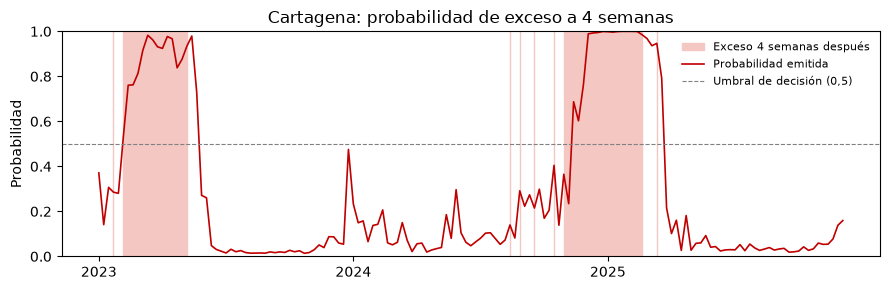

In [5]:
prob = []
for i in cartagena.index[4:]:
    h = cartagena.loc[:i, ["casos", "umbral_canal"]]
    prob.append(md.predecir(h, "cartagena", cartagena.loc[i, "umbral_objetivo"])["probabilidad_exceso"])
cartagena.loc[cartagena.index[4:], "prob"] = prob

t = cartagena[(cartagena["ANO"] >= 2023) & cartagena["target_brote_t4"].notna()].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3))
x = np.arange(len(t))
ax.fill_between(x, 0, 1, where=t["target_brote_t4"] == 1, color="#f4c7c3", step="mid", label="Exceso 4 semanas después")
ax.plot(x, t["prob"], color="#c00000", lw=1.2, label="Probabilidad emitida")
ax.axhline(UMBRAL_DECISION, color="grey", ls="--", lw=0.8, label="Umbral de decisión (0,5)")
marcas = t.index[t["SEMANA"] == 1]
ax.set_xticks(marcas, t.loc[marcas, "ANO"])
ax.set_ylim(0, 1); ax.set_ylabel("Probabilidad"); ax.set_title("Cartagena: probabilidad de exceso a 4 semanas")
ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 5. Última semana disponible en los 5 municipios

In [6]:
filas = []
for m in md.municipios_disponibles():
    df = cargar(m)
    i = df["umbral_objetivo"].last_valid_index()
    r = md.predecir(df.loc[:i, ["casos", "umbral_canal"]], m, df.loc[i, "umbral_objetivo"])
    filas.append({"municipio": m, "corte": f"{df.loc[i, 'ANO']}-S{df.loc[i, 'SEMANA']:02d}",
                  "casos": int(df.loc[i, "casos"]), "umbral_canal": round(df.loc[i, "umbral_canal"], 1),
                  "probabilidad": round(r["probabilidad_exceso"], 3),
                  "alerta": r["probabilidad_exceso"] >= UMBRAL_DECISION})
pd.DataFrame(filas)

,municipio,corte,casos,umbral_canal,probabilidad,alerta
0,cartagena,2025-S49,225,411.1,0.159,False
1,el_carmen_de_bolivar,2025-S49,5,29.1,0.094,False
2,magangue,2025-S49,6,24.4,0.057,False
3,santa_rosa_del_sur,2025-S49,1,10.2,0.064,False
4,turbaco,2025-S49,9,17.7,0.185,False
